# Cognifyz Data Science Internship
## Level 1 — Task 3: Geospatial Analysis

**Objective:** Explore restaurant locations using latitude and longitude, examine restaurant distribution across cities and countries, and investigate whether location coordinates are associated with aggregate ratings.

### Analysis plan
1. Load and validate the dataset.
2. Check geographic coordinates and rating values.
3. Summarize restaurant distribution by country and city.
4. Visualize restaurant locations and rating patterns.
5. Calculate correlations between coordinates and aggregate rating.
6. Present data-driven findings and limitations.

**Dataset path:** `../dataset/Dataset.csv`  
**Note:** Run this notebook from the `Level1` folder so the relative path resolves correctly.

## 1. Import libraries

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [4]:
DATA_PATH = Path("../dataset/Dataset.csv")
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 9,551 rows × 21 columns


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenue, Poblacion, Makati City","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Makati City",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Makati City",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Mandaluyong City",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandaluyong City",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


## 3. Validate geographic and rating fields
Check required columns, data types, missing values, coordinate ranges, and rating coverage before plotting.

In [5]:
required_columns = ["Restaurant ID", "Restaurant Name", "Country Code", "City",
                    "Longitude", "Latitude", "Aggregate rating"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from dataset: {missing_columns}")

for col in ["Longitude", "Latitude", "Aggregate rating"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

validation = pd.DataFrame({
    "Data type": df[["Longitude", "Latitude", "Aggregate rating"]].dtypes.astype(str),
    "Missing values": df[["Longitude", "Latitude", "Aggregate rating"]].isna().sum(),
    "Unique values": df[["Longitude", "Latitude", "Aggregate rating"]].nunique()
})
display(validation)

print("Rows with missing coordinates:", int(df[["Longitude", "Latitude"]].isna().any(axis=1).sum()))
print("Rows with coordinates outside valid latitude/longitude bounds:",
      int((~df["Latitude"].between(-90, 90) | ~df["Longitude"].between(-180, 180)).fillna(True).sum()))
print("Rows with missing city:", int(df["City"].isna().sum()))
print("Rows with missing country code:", int(df["Country Code"].isna().sum()))
print("Aggregate rating range:", df["Aggregate rating"].min(), "to", df["Aggregate rating"].max())

,Data type,Missing values,Unique values
Longitude,float64,0,8120
Latitude,float64,0,8677
Aggregate rating,float64,0,33


Rows with missing coordinates: 0
Rows with coordinates outside valid latitude/longitude bounds: 0
Rows with missing city: 0
Rows with missing country code: 0
Aggregate rating range: 0.0 to 4.9


## 4. Prepare geospatial analysis data
Exclude records without valid coordinates from map-based analysis. Keep the original dataframe unchanged.

In [6]:
geo_df = df.dropna(subset=["Latitude", "Longitude"]).copy()
geo_df = geo_df[
    geo_df["Latitude"].between(-90, 90) &
    geo_df["Longitude"].between(-180, 180)
].copy()

print(f"Records available for geographic analysis: {len(geo_df):,} of {len(df):,}")
print(f"Records excluded due to missing/invalid coordinates: {len(df) - len(geo_df):,}")

display(geo_df[["Restaurant Name", "City", "Country Code", "Latitude",
                "Longitude", "Aggregate rating"]].head())

Records available for geographic analysis: 9,551 of 9,551
Records excluded due to missing/invalid coordinates: 0


,Restaurant Name,City,Country Code,Latitude,Longitude,Aggregate rating
0,Le Petit Souffle,Makati City,162,14.565443,121.027535,4.8
1,Izakaya Kikufuji,Makati City,162,14.553708,121.014101,4.5
2,Heat - Edsa Shangri-La,Mandaluyong City,162,14.581404,121.056831,4.4
3,Ooma,Mandaluyong City,162,14.585318,121.056475,4.9
4,Sambo Kojin,Mandaluyong City,162,14.584450,121.057508,4.8


## 5. Restaurant distribution by country
The dataset uses `Country Code` as its country identifier. The chart shows the countries with the most listed restaurants.

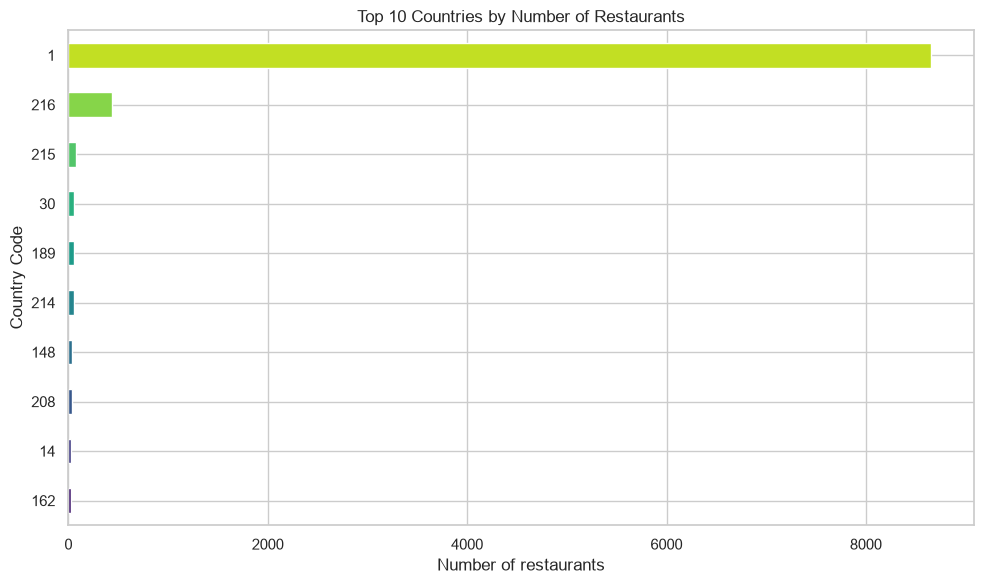

,Country Code,Restaurant Count
0,1,8652
1,216,434
2,215,80
3,30,60
4,214,60
5,189,60
6,148,40
7,208,34
8,14,24
9,162,22


In [7]:
country_counts = geo_df["Country Code"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
country_counts.plot(kind="barh", color=sns.color_palette("viridis", len(country_counts)))
plt.title("Top 10 Countries by Number of Restaurants")
plt.xlabel("Number of restaurants")
plt.ylabel("Country Code")
plt.tight_layout()
plt.show()

display(geo_df["Country Code"].value_counts().head(10).rename_axis("Country Code")
        .reset_index(name="Restaurant Count"))

In [16]:
try:
    import folium
    from folium.plugins import MarkerCluster

    # Sample deterministically when the dataset is large, to keep the map responsive.
    map_limit = min(2500, len(geo_df))
    map_df = geo_df.sample(n=map_limit, random_state=42) if len(geo_df) > map_limit else geo_df.copy()

    center = [map_df["Latitude"].median(), map_df["Longitude"].median()]
    restaurant_map = folium.Map(location=center, zoom_start=2, tiles="OpenStreetMap")
    cluster = MarkerCluster(name="Restaurants").add_to(restaurant_map)

    def rating_color(rating):
        if pd.isna(rating):
            return "gray"
        if rating >= 4.0:
            return "green"
        if rating >= 3.0:
            return "orange"
        return "red"

    for _, row in map_df.iterrows():
        rating = row.get("Aggregate rating", np.nan)
        name = str(row.get("Restaurant Name", "Unknown restaurant"))
        city = str(row.get("City", "Unknown city"))
        country = str(row.get("Country Code", "Unknown"))
        popup_text = (
            f"<b>{name}</b><br>"
            f"City: {city}<br>"
            f"Country Code: {country}<br>"
            f"Aggregate rating: {rating if pd.notna(rating) else 'N/A'}"
        )
        folium.CircleMarker(
            location=[row["Latitude"], row["Longitude"]],
            radius=4,
            color=rating_color(rating),
            fill=True,
            fill_opacity=0.7,
            popup=folium.Popup(popup_text, max_width=300),
            tooltip=name
        ).add_to(cluster)

    folium.LayerControl().add_to(restaurant_map)
    display(restaurant_map)
    print(f"Map displays {len(map_df):,} restaurant records.")
except ImportError:
    print("Folium is not installed. Install it with: pip install folium")
except Exception as exc:
    print(f"Interactive map could not be rendered in this environment: {exc}")

Map displays 2,500 restaurant records.


## 6. Restaurant distribution by city
City names can occur in different countries, so this chart ranks city labels as recorded in the dataset.

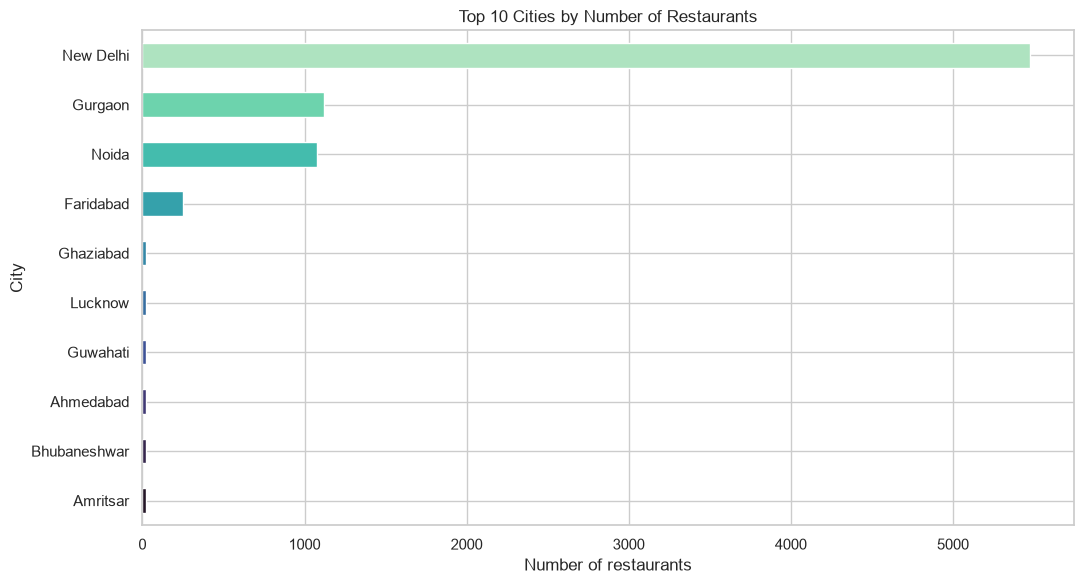

,City,Restaurant Count
0,New Delhi,5473
1,Gurgaon,1118
2,Noida,1080
3,Faridabad,251
4,Ghaziabad,25
5,Ahmedabad,21
6,Amritsar,21
7,Bhubaneshwar,21
8,Guwahati,21
9,Lucknow,21


In [8]:
city_counts = geo_df["City"].dropna().value_counts().head(10).sort_values()

plt.figure(figsize=(11, 6))
city_counts.plot(kind="barh", color=sns.color_palette("mako", len(city_counts)))
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of restaurants")
plt.ylabel("City")
plt.tight_layout()
plt.show()

display(geo_df["City"].value_counts().head(10).rename_axis("City")
        .reset_index(name="Restaurant Count"))

## 7. Global restaurant location overview
This scatter plot uses longitude and latitude as geographic coordinates. Each point represents a restaurant; color represents aggregate rating. With a global dataset, dense areas may overlap, so use the interactive map below to inspect individual records.

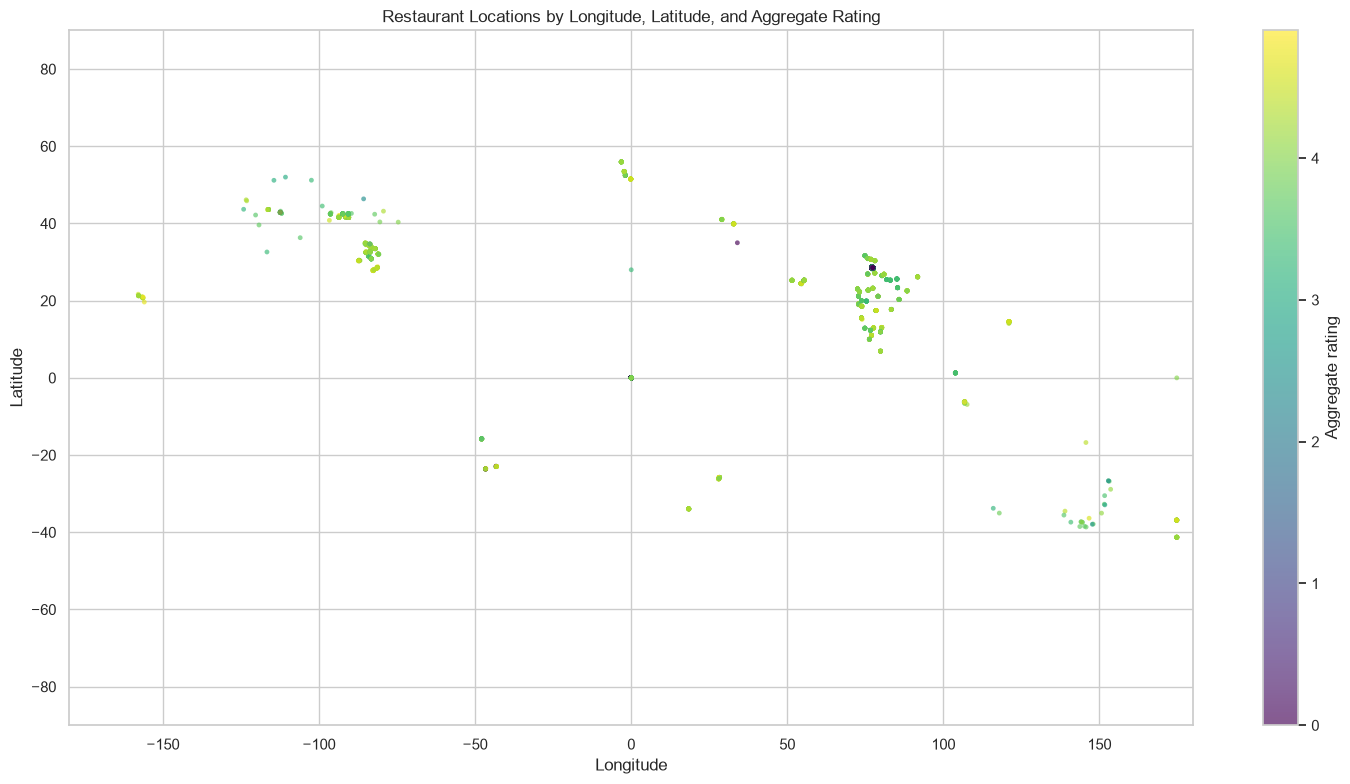

In [9]:
plot_df = geo_df.dropna(subset=["Aggregate rating"]).copy()

plt.figure(figsize=(15, 8))
scatter = plt.scatter(
    plot_df["Longitude"], plot_df["Latitude"],
    c=plot_df["Aggregate rating"], cmap="viridis",
    s=12, alpha=0.65, linewidths=0
)
plt.colorbar(scatter, label="Aggregate rating")
plt.title("Restaurant Locations by Longitude, Latitude, and Aggregate Rating")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.tight_layout()
plt.show()

## 8. Interactive restaurant map (Folium)

The map uses a manageable sample of restaurants for browser performance. If Folium is not installed, run `pip install folium` in your notebook environment and rerun this cell. The sample is for visualization only; the statistical analysis continues to use all valid records.

In [1]:
%pip install folium


   ---------------- ----------------------- 2/5 [jinja2]
   ---------------- ----------------------- 2/5 [jinja2]
   ------------------------ --------------- 3/5 [branca]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   -------------------------------- ------- 4/5 [folium]
   ---------------------------------------- 5/5 [folium]

Note: you may need to restart the kernel to use updated packages.


## 9. Relationship between location and aggregate rating
Pearson correlation is calculated between latitude/longitude and aggregate rating. These are global coordinate correlations, not proof that a location causes a rating to change. Geographic clustering, country-level differences, and uneven dataset coverage can affect the results.

,Latitude,Longitude,Aggregate rating
Latitude,1.000,0.043,0.001
Longitude,0.043,1.000,-0.117
Aggregate rating,0.001,-0.117,1.000


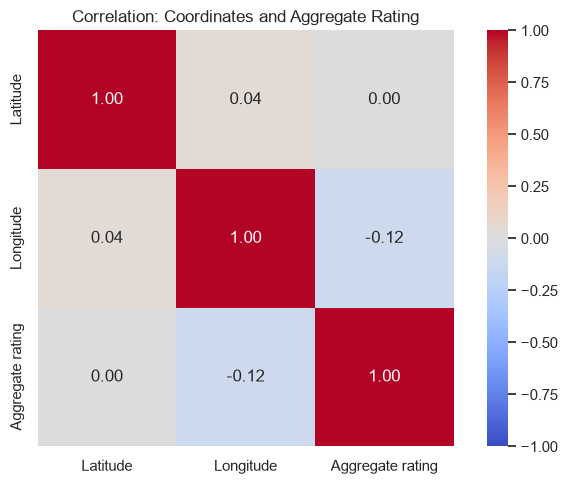

Pearson correlation (Latitude vs Aggregate rating): 0.001
Pearson correlation (Longitude vs Aggregate rating): -0.117


In [9]:
corr_data = geo_df[["Latitude", "Longitude", "Aggregate rating"]].dropna()
correlation_matrix = corr_data.corr(method="pearson")

display(correlation_matrix.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation: Coordinates and Aggregate Rating")
plt.tight_layout()
plt.show()

for coordinate in ["Latitude", "Longitude"]:
    corr_value = corr_data[coordinate].corr(corr_data["Aggregate rating"])
    print(f"Pearson correlation ({coordinate} vs Aggregate rating): {corr_value:.3f}")

## 10. Compare average ratings across high-count cities
Only cities with enough observations to appear in the top 10 by count are included. This compares averages descriptively; it does not adjust for cuisine, price range, or other factors.

,Restaurant_Count,Average_Rating,Median_Rating,Latitude_Mean,Longitude_Mean
City,,,,,
New Delhi,5473,2.439,3.1,27.398,73.904
Gurgaon,1118,2.651,3.2,27.245,73.763
Noida,1080,2.036,2.8,26.107,70.627
Faridabad,251,1.867,2.8,25.941,70.535
Ghaziabad,25,2.852,3.2,28.637,77.362
Ahmedabad,21,4.162,4.2,23.037,72.531
Amritsar,21,3.686,3.6,25.611,60.613
Bhubaneshwar,21,3.981,4.0,16.453,69.478
Lucknow,21,4.195,4.2,21.738,65.553


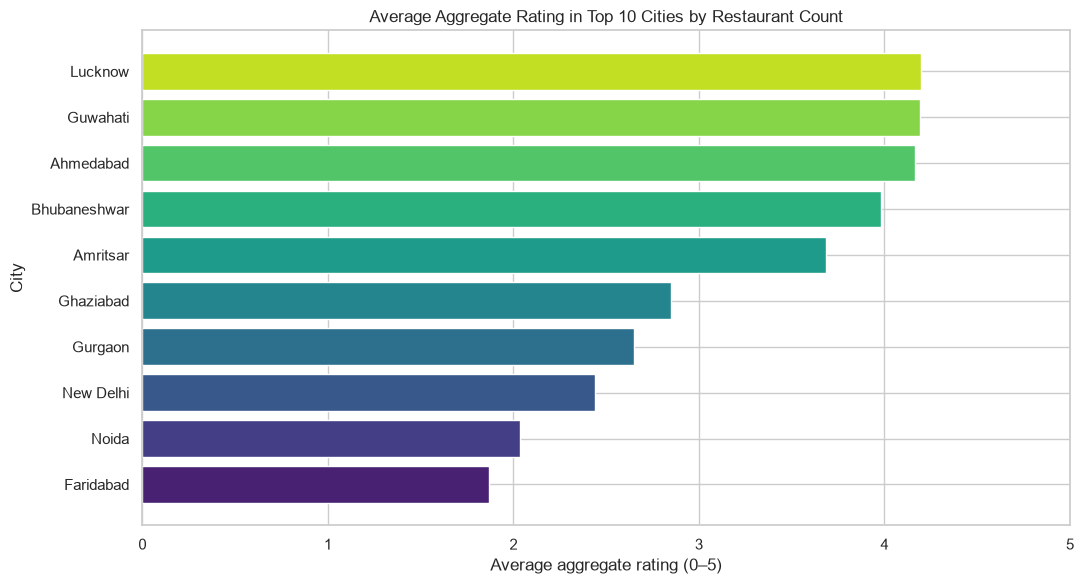

In [10]:
top_cities = geo_df["City"].value_counts().head(10).index
city_summary = (
    geo_df[geo_df["City"].isin(top_cities)]
    .groupby("City")
    .agg(
        Restaurant_Count=("Restaurant ID", "count"),
        Average_Rating=("Aggregate rating", "mean"),
        Median_Rating=("Aggregate rating", "median"),
        Latitude_Mean=("Latitude", "mean"),
        Longitude_Mean=("Longitude", "mean")
    )
    .sort_values("Restaurant_Count", ascending=False)
    .round(3)
)
display(city_summary)

rating_plot = city_summary.sort_values("Average_Rating")
plt.figure(figsize=(11, 6))
plt.barh(rating_plot.index, rating_plot["Average_Rating"],
         color=sns.color_palette("viridis", len(rating_plot)))
plt.xlim(0, 5)
plt.title("Average Aggregate Rating in Top 10 Cities by Restaurant Count")
plt.xlabel("Average aggregate rating (0–5)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

## 11. Automatically generated findings
The statements below are calculated from the dataset at runtime. Review them alongside the plots before drawing conclusions.

In [11]:
print("GEOSPATIAL ANALYSIS — KEY FINDINGS")
print("=" * 45)

print(f"1. Dataset records: {len(df):,}; records with valid coordinates: {len(geo_df):,}.")

if not geo_df.empty:
    top_country = geo_df["Country Code"].value_counts().idxmax()
    top_country_count = int(geo_df["Country Code"].value_counts().max())
    print(f"2. Country code with the most restaurant records: {top_country} ({top_country_count:,}).")

    city_freq = geo_df["City"].dropna().value_counts()
    if not city_freq.empty:
        print(f"3. City with the most restaurant records: {city_freq.index[0]} ({int(city_freq.iloc[0]):,}).")

    valid_ratings = geo_df["Aggregate rating"].dropna()
    if not valid_ratings.empty:
        print(f"4. Mean aggregate rating among geographically valid records: {valid_ratings.mean():.2f}.")

    for coordinate in ["Latitude", "Longitude"]:
        corr_value = corr_data[coordinate].corr(corr_data["Aggregate rating"])
        print(f"5. Correlation of {coordinate.lower()} with aggregate rating: {corr_value:.3f}.")

print("\nInterpretation note: coordinate correlations are descriptive and do not establish causation.")
print("Country Code is shown as supplied by the dataset; it has not been converted to country names.")

GEOSPATIAL ANALYSIS — KEY FINDINGS
1. Dataset records: 9,551; records with valid coordinates: 9,551.
2. Country code with the most restaurant records: 1 (8,652).
3. City with the most restaurant records: New Delhi (5,473).
4. Mean aggregate rating among geographically valid records: 2.67.
5. Correlation of latitude with aggregate rating: 0.001.
5. Correlation of longitude with aggregate rating: -0.117.

Interpretation note: coordinate correlations are descriptive and do not establish causation.
Country Code is shown as supplied by the dataset; it has not been converted to country names.


## 12. Conclusion

This notebook visualizes restaurant coordinates, summarizes the geographic distribution by country code and city, and evaluates the linear association between latitude/longitude and aggregate rating.

### Reporting checklist
- State the number of rows retained for geographic analysis and any exclusions.
- Report the top country code and city using the generated tables.
- Describe visible geographic clusters without claiming that the map is a complete or uniform sample of the world.
- Report the coordinate–rating correlations with their limitations.
- Do not interpret correlation as causation.

**Task completed:** Level 1 — Task 3: Geospatial Analysis.